# In-Hospital Mortality Analysis

**Question:** which factors are associated with in-hospital mortality in seriously ill patients?

**Data:** SUPPORT2 dataset (Vanderbilt University, Department of Biostatistics).
It contains 9105 seriously ill adults hospitalized in 5 US medical centers (1989-1994).
The target variable is `hospdead`: 1 if the patient died in hospital, 0 otherwise.

In [1]:
from src.data_loader import load_data
from src.cleaning import clean_data
from src.analysis import mortality_by_group, add_age_group, chi_square_test, compare_survived_died
from src.plots import plot_mortality_by_group, plot_survived_vs_died

In [2]:
df_raw = load_data()
df = clean_data(df_raw)
df = add_age_group(df)

Loaded 9105 patients and 47 columns
Dropped columns: ['urine', 'adlp']
hrt: 83 zeros replaced with NaN
resp: 65 zeros replaced with NaN
meanbp: 51 zeros replaced with NaN


## Data cleaning

| Problem | Decision | Reason |
| ------- | -------- | ------ |
| `adlp` and `urine` have more than 50% missing values | Drop the columns | Too much missing data to be reliable |
| `hrt`, `resp`, `meanbp` contain zeros | Replace with NaN | Impossible values for a living patient |
| `income` is missing for 33% of patients | Fill with "unknown" | Missing values are not random (more deaths) |
| `scoma` has many zeros | Keep them | 0 means fully conscious |

## 1. Which diseases are the most lethal?


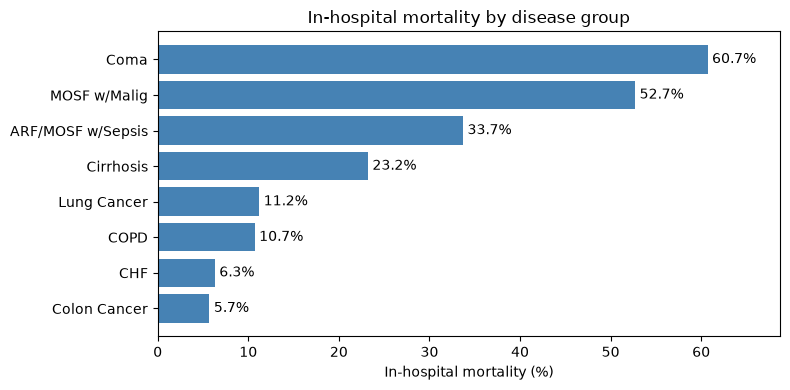

In [3]:
table = mortality_by_group(df, "dzgroup")
plot_mortality_by_group(table, "In-hospital mortality by disease group",
                        "figures/mortality_dzgroup.png")

In [4]:
p = chi_square_test(df, "dzgroup")
print(f"Chi-square test: p-value = {p:.4f}")

Chi-square test: p-value = 0.0000


**Findings:** coma has the highest in-hospital mortality (60.7%), followed by multiple organ failure with malignancy (52.7%).
Colon cancer (5.7%) and heart failure (6.3%) have the lowest.
The difference between disease groups is statistically significant (p < 0.001).